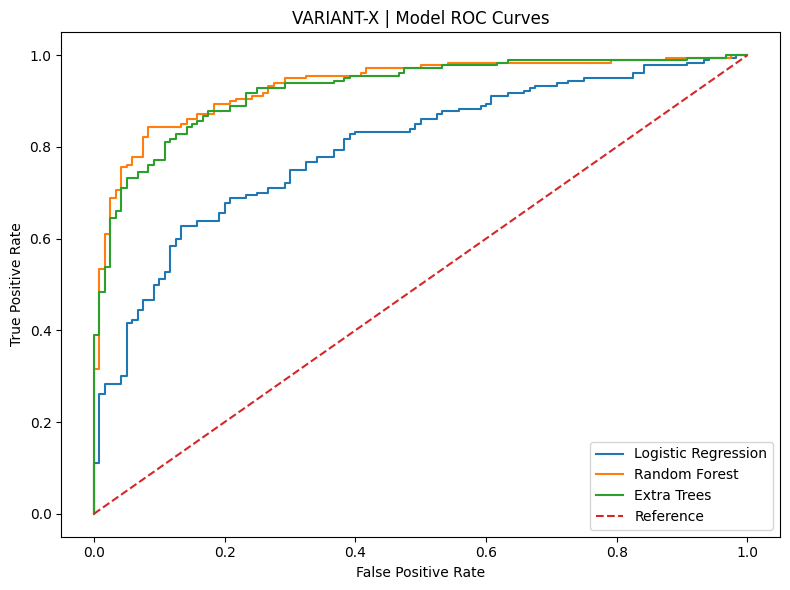

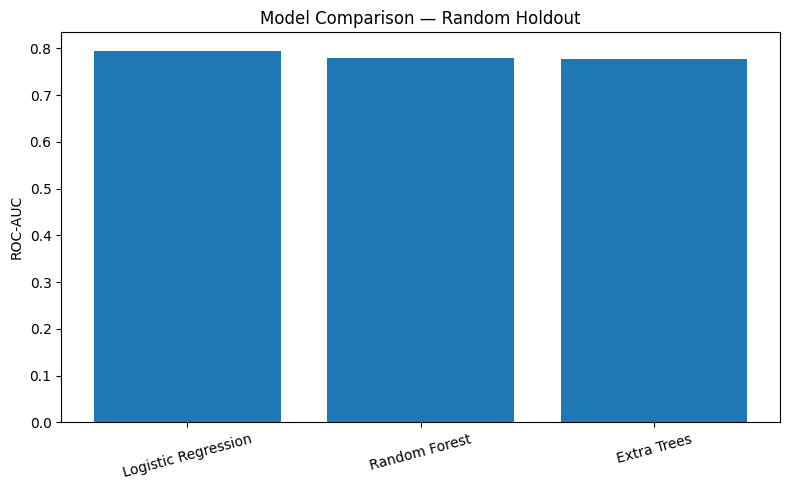

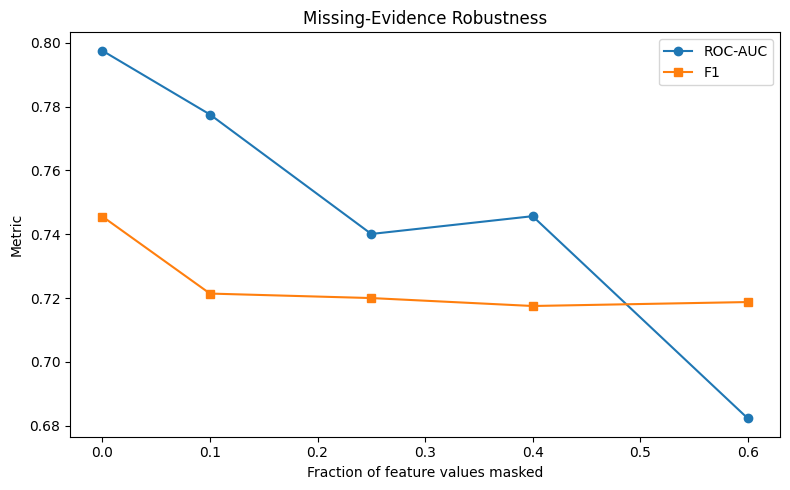

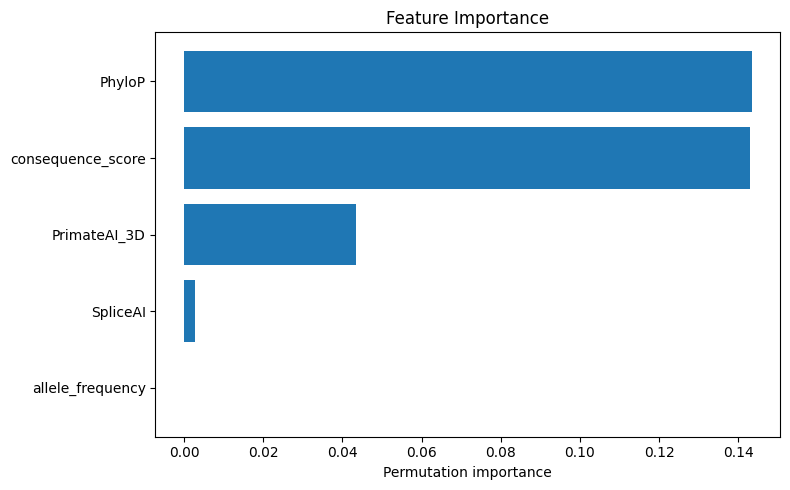


VARIANT-X AI COMPLETED SUCCESSFULLY
Selected model: Logistic Regression

Model metrics:
              model     validation  accuracy  precision   recall       f1  roc_auc   pr_auc  brier_score
Logistic Regression random_holdout  0.720000   0.807692 0.700000 0.750000 0.794583 0.860431     0.186167
      Random Forest random_holdout  0.726667   0.763441 0.788889 0.775956 0.778981 0.846036     0.187070
        Extra Trees random_holdout  0.716667   0.798742 0.705556 0.749263 0.778287 0.848947     0.191792

Project folder: /content/VARIANT-X
ZIP archive: /content/VARIANT-X.zip

Files created:
 - .gitignore
 - README.md
 - app.py
 - demo_variants.csv
 - models/best_model.joblib
 - models/metadata.json
 - outputs/data_audit.json
 - outputs/feature_importance.csv
 - outputs/figures/feature_importance.png
 - outputs/figures/model_comparison.png
 - outputs/figures/robustness.png
 - outputs/figures/roc_curves.png
 - outputs/gene_grouped_metrics.csv
 - outputs/metrics.csv
 - outputs/missingness_

In [2]:

# ================================================================
# VARIANT-X AI — FIXED GOOGLE COLAB VERSION
# ONE CELL | ML MODELS | EVALUATION | VISUALIZATIONS | GITHUB FILES
# ================================================================

import sys, subprocess, importlib.util, json, zipfile, textwrap
from pathlib import Path

# 1. Install only missing dependencies
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "joblib": "joblib",
}

missing = [pkg for module, pkg in packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q"] + missing
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve
)
from sklearn.inspection import permutation_importance

# 2. Create project folders
PROJECT = Path("/content/VARIANT-X")
OUT = PROJECT / "outputs"
FIG = OUT / "figures"
MODELS = PROJECT / "models"

for folder in [OUT, FIG, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)

# 3. Generate clearly labelled synthetic demo data
n = 1200
genes = rng.choice([f"GENE_{i:03d}" for i in range(100)], n)

df = pd.DataFrame({
    "gene": genes,
    "PhyloP": rng.normal(0, 1, n),
    "SpliceAI": rng.beta(1.5, 5, n),
    "PrimateAI_3D": rng.normal(0, 1, n),
    "allele_frequency": rng.beta(0.5, 15, n),
    "consequence_score": rng.choice([0, 1, 2], n)
})

logits = (
    -0.8 + 0.9 * df["PhyloP"]
    + 1.7 * df["SpliceAI"]
    + 0.7 * df["PrimateAI_3D"]
    + 1.2 * df["consequence_score"]
    - 2.5 * df["allele_frequency"]
)

probability = 1 / (1 + np.exp(-logits))
df["target"] = rng.binomial(1, probability)
df["variant_id"] = [f"DEMO_{i:06d}" for i in range(n)]
df["data_origin"] = "SYNTHETIC_DEMO"

# Introduce missing values to test preprocessing
for col in ["PhyloP", "SpliceAI", "PrimateAI_3D"]:
    mask = rng.random(n) < 0.12
    df.loc[mask, col] = np.nan

# Save demonstration dataset
df.to_csv(PROJECT / "demo_variants.csv", index=False)

# 4. Dataset audit
audit = {
    "data_origin": "synthetic_demo",
    "rows": int(len(df)),
    "columns": int(len(df.columns)),
    "duplicate_rows": int(df.duplicated().sum()),
    "missing_fraction": {
        k: float(v) for k, v in df.isna().mean().items()
    },
    "target_distribution": {
        str(k): int(v) for k, v in df["target"].value_counts().items()
    }
}

(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2))

# 5. Prepare features and holdout split
feature_cols = [
    "PhyloP", "SpliceAI", "PrimateAI_3D",
    "allele_frequency", "consequence_score"
]

X = df[feature_cols]
y = df["target"]

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.25,
    random_state=SEED,
    stratify=y
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 6. Define three models
model_specs = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=-1
    )
}

def evaluate(y_true, scores):
    predictions = (scores >= 0.5).astype(int)
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(
            y_true, predictions, zero_division=0
        )),
        "recall": float(recall_score(
            y_true, predictions, zero_division=0
        )),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "pr_auc": float(average_precision_score(y_true, scores)),
        "brier_score": float(brier_score_loss(y_true, scores))
    }

models = {}
metrics = []
prediction_frames = []

# 7. Train and evaluate models
for name, estimator in model_specs.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    scores = pipeline.predict_proba(X_test)[:, 1]
    metrics.append({
        "model": name,
        "validation": "random_holdout",
        **evaluate(y_test, scores)
    })
    models[name] = pipeline

    prediction_frames.append(pd.DataFrame({
        "variant_id": df.iloc[test_idx]["variant_id"].values,
        "gene": df.iloc[test_idx]["gene"].values,
        "actual_target": y_test.values,
        "predicted_score": scores,
        "predicted_label": (scores >= 0.5).astype(int),
        "model": name
    }))

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(OUT / "metrics.csv", index=False)

predictions_df = pd.concat(prediction_frames, ignore_index=True)
predictions_df.to_csv(OUT / "predictions.csv", index=False)

# 8. Gene-grouped validation
# Entire genes are held together in each fold.
grouped_results = []
groups = df["gene"].astype(str)

if groups.nunique() >= 3:
    cv = GroupKFold(n_splits=5)

    for name, estimator in model_specs.items():
        for fold, (tr, te) in enumerate(
            cv.split(X, y, groups=groups), start=1
        ):
            if y.iloc[tr].nunique() < 2 or y.iloc[te].nunique() < 2:
                continue

            pipeline = Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median", add_indicator=True
                )),
                ("scaler", StandardScaler()),
                ("model", estimator)
            ])

            pipeline.fit(X.iloc[tr], y.iloc[tr])
            scores = pipeline.predict_proba(X.iloc[te])[:, 1]

            grouped_results.append({
                "model": name,
                "validation": "gene_grouped_cv",
                "fold": fold,
                **evaluate(y.iloc[te], scores)
            })

if grouped_results:
    pd.DataFrame(grouped_results).to_csv(
        OUT / "gene_grouped_metrics.csv", index=False
    )

# 9. Select model using holdout ROC-AUC
best_name = metrics_df.sort_values(
    "roc_auc", ascending=False
).iloc[0]["model"]

best_model = models[best_name]
joblib.dump(best_model, MODELS / "best_model.joblib")

metadata = {
    "selected_model": best_name,
    "features": feature_cols,
    "data_origin": "synthetic_demo",
    "threshold": 0.5,
    "clinical_use": False
}
(MODELS / "metadata.json").write_text(json.dumps(metadata, indent=2))

# 10. Missing-data robustness experiment
robustness_results = []
stress_rng = np.random.default_rng(SEED + 1)

for fraction in [0.0, 0.10, 0.25, 0.40, 0.60]:
    masked = X_test.copy()

    if fraction > 0:
        mask = stress_rng.random(masked.shape) < fraction
        masked = masked.mask(mask)

    scores = best_model.predict_proba(masked)[:, 1]

    robustness_results.append({
        "masked_fraction": fraction,
        "model": best_name,
        **evaluate(y_test, scores)
    })

robustness_df = pd.DataFrame(robustness_results)
robustness_df.to_csv(
    OUT / "missingness_robustness.csv", index=False
)

# 11. Feature permutation importance
importance = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=5, random_state=SEED, scoring="roc_auc"
)

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

importance_df.to_csv(OUT / "feature_importance.csv", index=False)

# 12. Generate ROC curves
plt.figure(figsize=(8, 6))

for name, model in models.items():
    scores = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "--", label="Reference")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("VARIANT-X | Model ROC Curves")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "roc_curves.png", dpi=160)
plt.show()
plt.close()

# 13. Model comparison chart
plt.figure(figsize=(8, 5))
plt.bar(metrics_df["model"], metrics_df["roc_auc"])
plt.ylabel("ROC-AUC")
plt.title("Model Comparison — Random Holdout")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIG / "model_comparison.png", dpi=160)
plt.show()
plt.close()

# 14. Robustness chart
plt.figure(figsize=(8, 5))
plt.plot(
    robustness_df["masked_fraction"], robustness_df["roc_auc"],
    marker="o", label="ROC-AUC"
)
plt.plot(
    robustness_df["masked_fraction"], robustness_df["f1"],
    marker="s", label="F1"
)
plt.xlabel("Fraction of feature values masked")
plt.ylabel("Metric")
plt.title("Missing-Evidence Robustness")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "robustness.png", dpi=160)
plt.show()
plt.close()

# 15. Feature importance chart
top = importance_df.sort_values("importance_mean").tail(15)
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean"])
plt.xlabel("Permutation importance")
plt.title("Feature Importance")
plt.tight_layout()
plt.savefig(FIG / "feature_importance.png", dpi=160)
plt.show()
plt.close()

# 16. Create Streamlit dashboard file
app_code = r'''
import json
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st
import plotly.express as px

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "outputs"
MODEL = joblib.load(ROOT / "models" / "best_model.joblib")
META = json.loads((ROOT / "models" / "metadata.json").read_text())

st.set_page_config(page_title="VARIANT-X AI", layout="wide")
st.title("VARIANT-X AI")
st.subheader("Explainable Genomic Variant Reliability Research")
st.warning("Synthetic demonstration only. Not for clinical decisions.")

metrics = pd.read_csv(OUT / "metrics.csv")
st.markdown("### Model evaluation")
st.dataframe(metrics, use_container_width=True)

st.plotly_chart(
    px.bar(metrics, x="model", y="roc_auc", title="Model Comparison"),
    use_container_width=True
)

for filename in [
    "roc_curves.png", "model_comparison.png",
    "robustness.png", "feature_importance.png"
]:
    path = OUT / "figures" / filename
    if path.exists():
        st.image(str(path), caption=filename)

st.markdown("### Explore a research score")
with st.form("score_form"):
    values = {}
    cols = st.columns(2)

    for i, feature in enumerate(META["features"]):
        with cols[i % 2]:
            values[feature] = st.number_input(
                feature, value=0.0, format="%.6f"
            )

    submitted = st.form_submit_button("Calculate score")

if submitted:
    row = pd.DataFrame([values], columns=META["features"])
    score = float(MODEL.predict_proba(row)[0, 1])
    st.metric("Model score for class 1", f"{score:.3f}")
    st.caption(
        "This score is not necessarily calibrated and is not a "
        "clinical probability or diagnosis."
    )

pred_path = OUT / "predictions.csv"
if pred_path.exists():
    with st.expander("Download predictions"):
        pred = pd.read_csv(pred_path)
        st.dataframe(pred, use_container_width=True)
        st.download_button(
            "Download CSV", pred.to_csv(index=False),
            "variant_x_predictions.csv", "text/csv"
        )
'''

(PROJECT / "app.py").write_text(textwrap.dedent(app_code).lstrip())

# 17. Create README and requirements
readme = """
# VARIANT-X AI

Explainable ML research prototype for genomic variant prioritization.

## Features
- Logistic Regression, Random Forest, Extra Trees
- Dataset audit and missing-value imputation
- Random holdout evaluation
- Gene-grouped validation
- Missing-data stress testing
- Permutation feature importance
- Streamlit dashboard and downloadable predictions

## Run
Install requirements, then execute:
`python run_pipeline.py`
`streamlit run app.py`

The included data are synthetic and are not biological findings.
This software is not a diagnostic tool.
"""
(PROJECT / "README.md").write_text(textwrap.dedent(readme).strip())

(PROJECT / "requirements.txt").write_text(
    "numpy\npandas\nscikit-learn\nmatplotlib\njoblib\nstreamlit\nplotly\n"
)

(PROJECT / ".gitignore").write_text(
    "__pycache__/\n.venv/\nvenv/\n.env\n*.pyc\n"
)

# 18. Save ZIP for easy download from Colab
zip_path = Path("/content/VARIANT-X.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in PROJECT.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(PROJECT.parent))

# 19. Final summary
print("\n" + "=" * 60)
print("VARIANT-X AI COMPLETED SUCCESSFULLY")
print("=" * 60)
print("Selected model:", best_name)
print("\nModel metrics:")
print(metrics_df.to_string(index=False))
print("\nProject folder:", PROJECT)
print("ZIP archive:", zip_path)
print("\nFiles created:")
for file in sorted(PROJECT.rglob("*")):
    if file.is_file():
        print(" -", file.relative_to(PROJECT))

print("\nTo launch dashboard in Colab, run this in a NEW cell:")
print("%cd /content/VARIANT-X")
print("!streamlit run app.py")
print("\nRemember: synthetic data results are for software testing only.")
